In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import decimate
from src.config import CWRU_RAW
from src.cwru_meta import build_metadata
from src.data_loader import load_cwru_file
from src.cwru_reference import MULT
from src.dataset import build_cwru_windows
from src.signal_proc import (WIN_LEN, time_features, amplitude_spectrum,
                             envelope_spectrum, peak_to_floor, spectrogram_db)

meta = build_metadata().set_index("file_id")

def load(fid):
    r = meta.loc[fid]
    return load_cwru_file(CWRU_RAW / r.relpath, int(r.fs_native))

def env_of(fid):
    rec = load(fid)
    rpm = rec.rpm or meta.loc[fid, "nominal_rpm"]
    shaft = rpm / 60
    fe, me = envelope_spectrum(rec.signal, rec.fs)
    return rec, shaft, fe, me

X, info = build_cwru_windows() 

In [2]:
print(X.shape, info["label"].nunique())

(4643, 2048) 10


In [12]:
raw = load_cwru_file(CWRU_RAW / "normal" / "98.mat", 48000, target_fs=48000).signal
for name, s in [("decimate", decimate(raw, 4, zero_phase=True)), ("naive [::4]", raw[::4])]:
    f, m = amplitude_spectrum(s, 12000)
    band = (f > 2000) & (f < 4000)
    print(name, "mean level 2-4 kHz:", round(float(m[band].mean()), 5))

decimate mean level 2-4 kHz: 0.00018
naive [::4] mean level 2-4 kHz: 0.00019


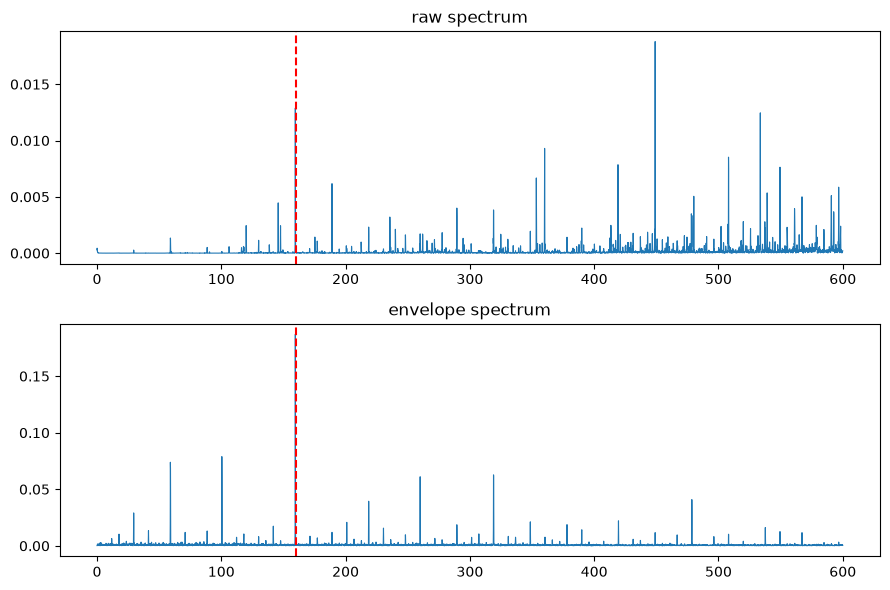

raw peak/floor at BPFI: 428.9  envelope: 272.6


In [13]:
rec, shaft, fe, me = env_of(106)
fr, mr = amplitude_spectrum(rec.signal, rec.fs)
f0 = MULT["BPFI"] * shaft
fig, ax = plt.subplots(2, 1, figsize=(9, 6))
for a, (f, m, t) in zip(ax, [(fr, mr, "raw spectrum"), (fe, me, "envelope spectrum")]):
    k = f < 600
    a.plot(f[k], m[k], lw=.8); a.axvline(f0, ls="--", c="r"); a.set_title(t)
plt.tight_layout(); plt.show()
print("raw peak/floor at BPFI:", round(peak_to_floor(fr, mr, f0), 1),
      " envelope:", round(peak_to_floor(fe, me, f0), 1))

In [14]:
tf = time_features(X.astype("float64"))
tab = pd.concat([info[["label", "load_hp"]], tf[["t_rms", "t_kurtosis", "t_crest"]]], axis=1)
tab.groupby(["label", "load_hp"]).mean().round(2).unstack("load_hp")

t_rms                   t_kurtosis                       \
load_hp              0     1     2     3          0      1      2      3   
label                                                                      
ball_0.007        0.14  0.14  0.15  0.15       2.96   2.96   2.83   2.89   
ball_0.014        0.15  0.14  0.14  0.13       9.02   7.14   7.11   8.15   
ball_0.021        0.13  0.12  0.11  0.12       4.07   4.22   3.26   3.09   
inner_race_0.007  0.29  0.29  0.30  0.31       5.40   5.54   5.56   5.28   
inner_race_0.014  0.20  0.16  0.16  0.18      22.02  21.31  21.24  17.88   
inner_race_0.021  0.52  0.44  0.49  0.45       7.39   7.63   7.98   8.31   
normal            0.07  0.06  0.06  0.06       2.77   2.97   2.96   3.05   
outer_race_0.007  0.67  0.59  0.57  0.58       7.63   7.58   7.85   7.96   
outer_race_0.014  0.10  0.09  0.10  0.09       3.01   2.93   3.01   3.44   
outer_race_0.021  0.58  0.56  0.57  0.56      20.08  20.61  21.52  21.33   

                 t_crest                    
load_hp                0     1     2     3  
label                                       
ball_0.007          3.54  3.51  3.38  3.48  
ball_0.014          6.43  5.93  6.12  6.32  
ball_0.021          4.41  4.43  3.81  3.63  
inner_race_0.007    5.12  4.91  4.74  4.46  
inner_race_0.014    8.62  9.03  8.97  8.72  
inner_race_0.021    6.00  5.85  5.69  6.07  
normal              3.42  3.57  3.64  3.72  
outer_race_0.007    4.90  4.96  4.99  5.08  
outer_race_0.014    3.60  3.57  3.62  4.03  
outer_race_0.021    8.49  8.61  8.77  8.57

In [4]:
import pandas as pd
from src.config import DATA_RAW

cm = DATA_RAW / "cmapss"
print((cm / "readme.txt").read_text(encoding="latin-1")[:1500])
for fd in ["FD001", "FD002", "FD003", "FD004"]:
    tr = pd.read_csv(cm / f"train_{fd}.txt", sep=r"\s+", header=None)
    te = pd.read_csv(cm / f"test_{fd}.txt", sep=r"\s+", header=None)
    rul = pd.read_csv(cm / f"RUL_{fd}.txt", sep=r"\s+", header=None)
    print(fd, "train", tr.shape, "engines", tr[0].nunique(),
          "| test", te.shape, "engines", te[0].nunique(), "| RUL rows", len(rul))
tr.head(3)

Data Set: FD001
Train trjectories: 100
Test trajectories: 100
Conditions: ONE (Sea Level)
Fault Modes: ONE (HPC Degradation)

Data Set: FD002
Train trjectories: 260
Test trajectories: 259
Conditions: SIX 
Fault Modes: ONE (HPC Degradation)

Data Set: FD003
Train trjectories: 100
Test trajectories: 100
Conditions: ONE (Sea Level)
Fault Modes: TWO (HPC Degradation, Fan Degradation)

Data Set: FD004
Train trjectories: 248
Test trajectories: 249
Conditions: SIX 
Fault Modes: TWO (HPC Degradation, Fan Degradation)



Experimental Scenario

Data sets consists of multiple multivariate time series. Each data set is further divided into training and test subsets. Each time series is from a different engine  i.e., the data can be considered to be from a fleet of engines of the same type. Each engine starts with different degrees of initial wear and manufacturing variation which is unknown to the user. This wear and variation is considered normal, i.e., it is not considered a fault condition. Th

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,...,129.78,2387.99,8074.83,9.3335,0.02,330,2212,100.0,10.62,6.3670
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,...,312.59,2387.73,8046.13,9.1913,0.02,361,2324,100.0,24.37,14.6552
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,...,129.62,2387.97,8066.62,9.4007,0.02,329,2212,100.0,10.48,6.4213


In [5]:
from src.cmapss import (load_cmapss, add_rul, ConditionScaler, N_CONDITIONS, SENSORS)
for fd in ["FD001", "FD004"]:
    train, test, rul_end = load_cmapss(fd)
    train = add_rul(train, cap=125)
    sc = ConditionScaler(N_CONDITIONS[fd]).fit(train)
    print(fd, "kept sensors:", len(sc.keep_), "dropped:", sorted(set(SENSORS) - set(sc.keep_)))
    if N_CONDITIONS[fd] > 1:
        print(sc._cond(train).value_counts().sort_index().to_dict())

FD001 kept sensors: 15 dropped: ['s1', 's10', 's16', 's18', 's19', 's5']
FD004 kept sensors: 17 dropped: ['s1', 's18', 's19', 's5']
{0: 15395, 1: 9224, 2: 9139, 3: 9091, 4: 9238, 5: 9162}


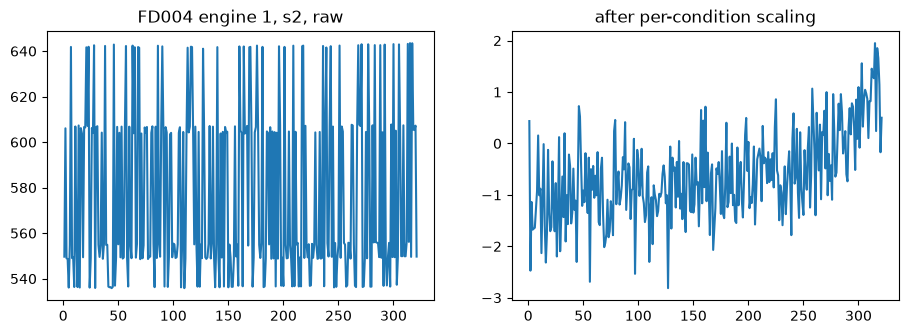

In [6]:
train, _, _ = load_cmapss("FD004"); train = add_rul(train)
sc = ConditionScaler(6).fit(train)
scaled = sc.transform(train)
g_raw, g_sc = train[train.unit == 1], scaled[scaled.unit == 1]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(g_raw.cycle, g_raw.s2); ax[0].set_title("FD004 engine 1, s2, raw")
ax[1].plot(g_sc.cycle, g_sc.s2); ax[1].set_title("after per-condition scaling")
plt.show()

In [11]:
train, _, _ = load_cmapss("FD004")
key = (train[["op1", "op2", "op3"]].round({"op1": 0, "op2": 2, "op3": 0}) + 0.0).astype(str).agg("/".join, axis=1)
print(key.value_counts())
sc = ConditionScaler(6).fit(train)
print(pd.crosstab(key, sc._cond(train)))

42.0/0.84/100.0    15395
0.0/0.0/100.0       9238
10.0/0.25/100.0     9224
35.0/0.84/100.0     9162
25.0/0.62/60.0      9139
20.0/0.7/100.0      9091
Name: count, dtype: int64
col_0                0     1     2     3     4     5
row_0                                               
0.0/0.0/100.0        0     0     0     0  9238     0
10.0/0.25/100.0      0  9224     0     0     0     0
20.0/0.7/100.0       0     0     0  9091     0     0
25.0/0.62/60.0       0     0  9139     0     0     0
35.0/0.84/100.0      0     0     0     0     0  9162
42.0/0.84/100.0  15395     0     0     0     0     0


In [8]:
train, test, rul_end = load_cmapss("FD001"); train = add_rul(train)
sc = ConditionScaler(1).fit(train)
rows = [(s, train[s].nunique(), round(train[s].corr(train["rul"], method="spearman"), 2)) for s in sc.keep_]
pd.DataFrame(rows, columns=["sensor", "n_unique", "spearman_vs_rul"]).sort_values("spearman_vs_rul", key=abs)


,sensor,n_unique,spearman_vs_rul
3,s6,2,-0.12
10,s14,6078,-0.21
6,s9,6403,-0.33
5,s8,53,-0.57
9,s13,56,-0.57
1,s3,3012,-0.61
0,s2,310,-0.63
12,s17,13,-0.64
14,s21,4745,0.66
13,s20,120,0.66
